# 07_01 – Аэропорты: объем, отмеченные уходы и качество покрытия

Полный описательный аудит актуальной выборки после 06. Анализируются все записи GoA=True и GoA=False. Единица учета – запись посадочного сегмента. Новые исключения не применяются.

Агрегаты формируются из корня проекта командой `.\.venv\Scripts\python.exe -u -X utf8 europe/scripts/audit_airports.py`. Ноутбук сверяет происхождение готовых агрегатов, показывает таблицы и отдельный график в каждой ячейке. Для пересчета агрегатов повторить указанную команду.

In [1]:
from pathlib import Path
import hashlib, json
import pandas as pd
from IPython.display import Image, display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'europe/scripts/audit_airports.py').exists())
REPORT = ROOT / 'europe/reports/airports'
FIGURES = ROOT / 'europe/figures/07_airports'
audit = json.loads((REPORT / '07_01_audit.json').read_text(encoding='utf8'))
with (ROOT / audit['input']).open('rb') as stream:
    assert hashlib.file_digest(stream, 'sha256').hexdigest() == audit['input_sha256']
summary = pd.read_csv(REPORT / 'airport_summary.csv')
assert int(summary.rows.sum()) == audit['rows']
assert int(summary.go_arounds.sum()) == audit['go_arounds']
assert int(summary.goa_false.sum()) == audit['goa_false']
display(Markdown(f"**{audit['airports']} аэропортов; {audit['rows']:,} строк; {audit['go_arounds']:,} GoA=True; {audit['goa_false']:,} GoA=False.**"))
display(summary)


**19 аэропортов; 6,331,485 строк; 18,349 GoA=True; 6,313,136 GoA=False.**

,airport,rows,go_arounds,goa_false,ga_percent,wilson_lower_percent,wilson_upper_percent,max_deviation_pp,days_with_records,days_without_records,source_days_without_records,unique_icao24,active_months
0,EGLL,631718,2400,629318,0.379916,0.365044,0.395392,0.015475,1575,36,27,5164,53
1,LFPG,617562,2346,615216,0.379881,0.364844,0.395535,0.015655,1588,23,23,6744,53
2,EDDF,604960,1884,603076,0.311426,0.297697,0.325785,0.014360,1464,147,147,7976,49
3,EHAM,561481,1038,560443,0.184868,0.173968,0.196450,0.011582,1465,146,146,8047,49
4,LEMD,515044,986,514058,0.191440,0.179868,0.203755,0.012315,1586,25,24,7357,53
5,EDDM,443203,1293,441910,0.291740,0.276286,0.308055,0.016315,1580,31,26,6921,53
6,LIRF,322749,466,322283,0.144385,0.131865,0.158091,0.013706,1587,24,23,6153,53
7,LSZH,316973,1144,315829,0.360914,0.340631,0.382400,0.021486,1586,25,25,6920,53
8,LOWW,293578,1021,292557,0.347778,0.327123,0.369733,0.021955,1587,24,24,6603,53
9,EIDW,263879,922,262957,0.349403,0.327600,0.372651,0.023248,1586,25,25,5690,53


## Объемы обеих групп

Объем в исходном источнике не равен числу реальных операций; небольшая группа не является автоматическим основанием удаления.

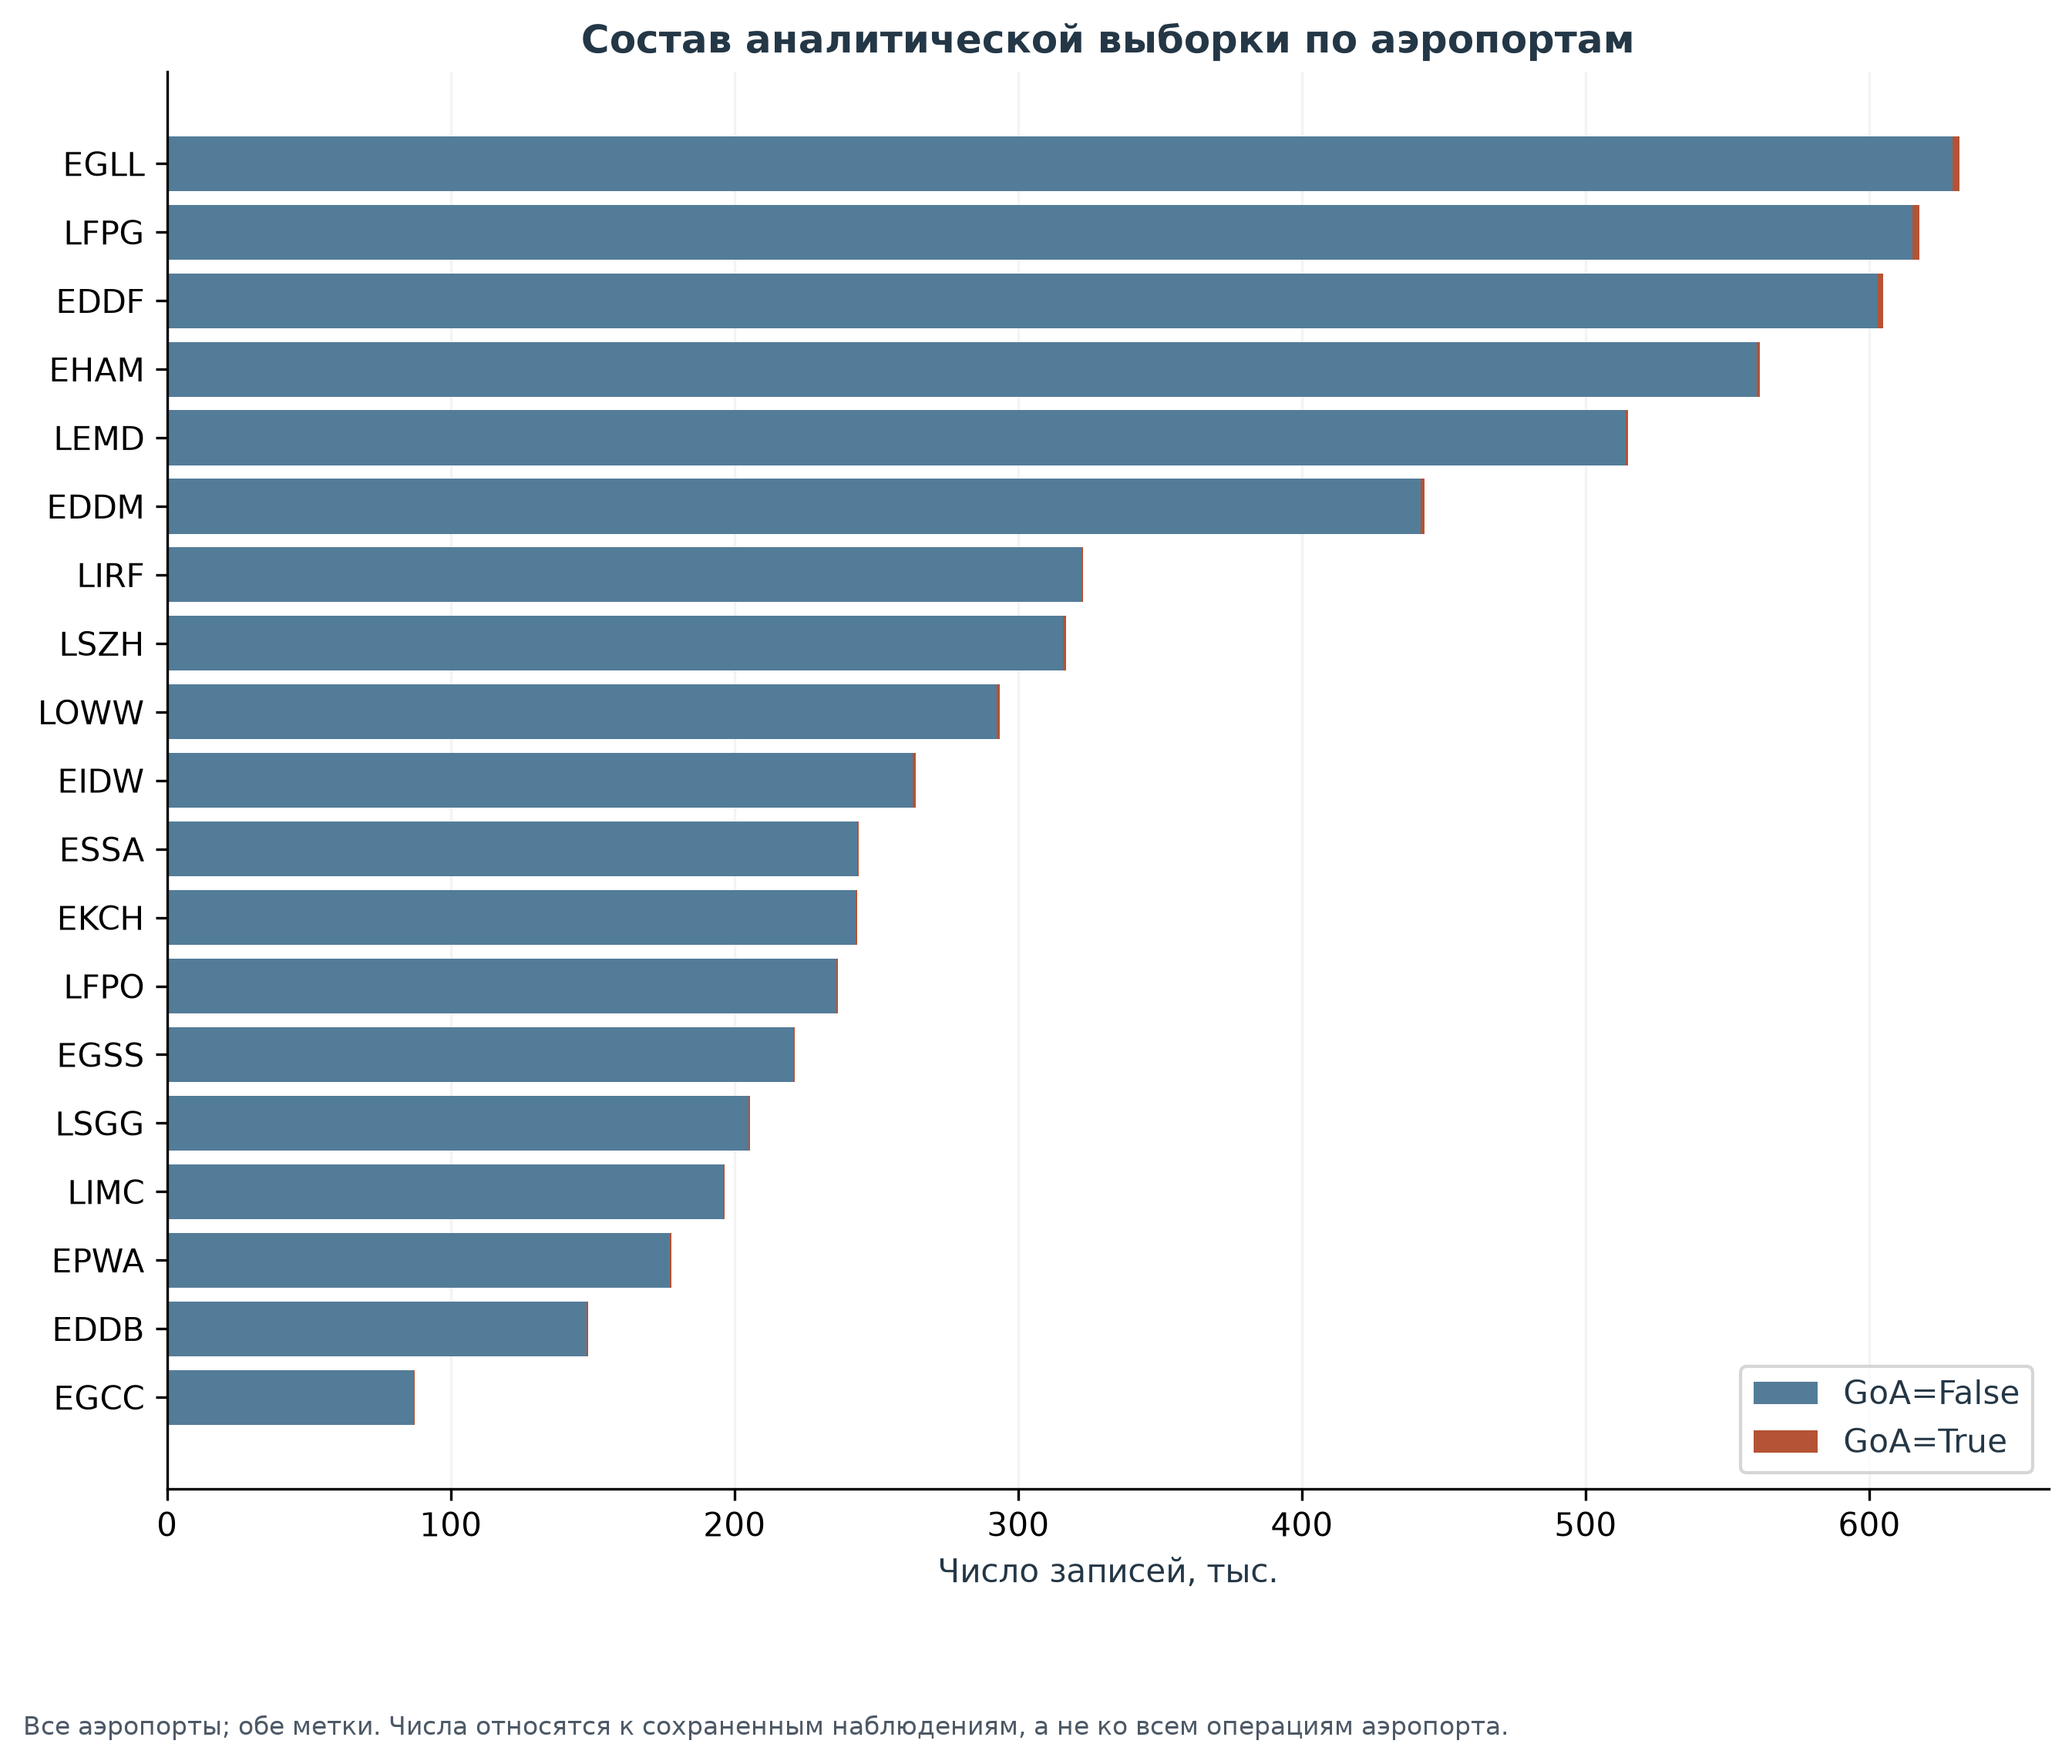

In [2]:
display(Image(filename=str(FIGURES / '07_01_airport_volume.png')))

## Частоты и неопределенность

Точечные 95% интервалы Уилсона предполагают независимость и общую вероятность внутри группы. Зависимость наблюдений и ошибка разметки не учтены. Доля GoA не является рейтингом безопасности аэропортов.

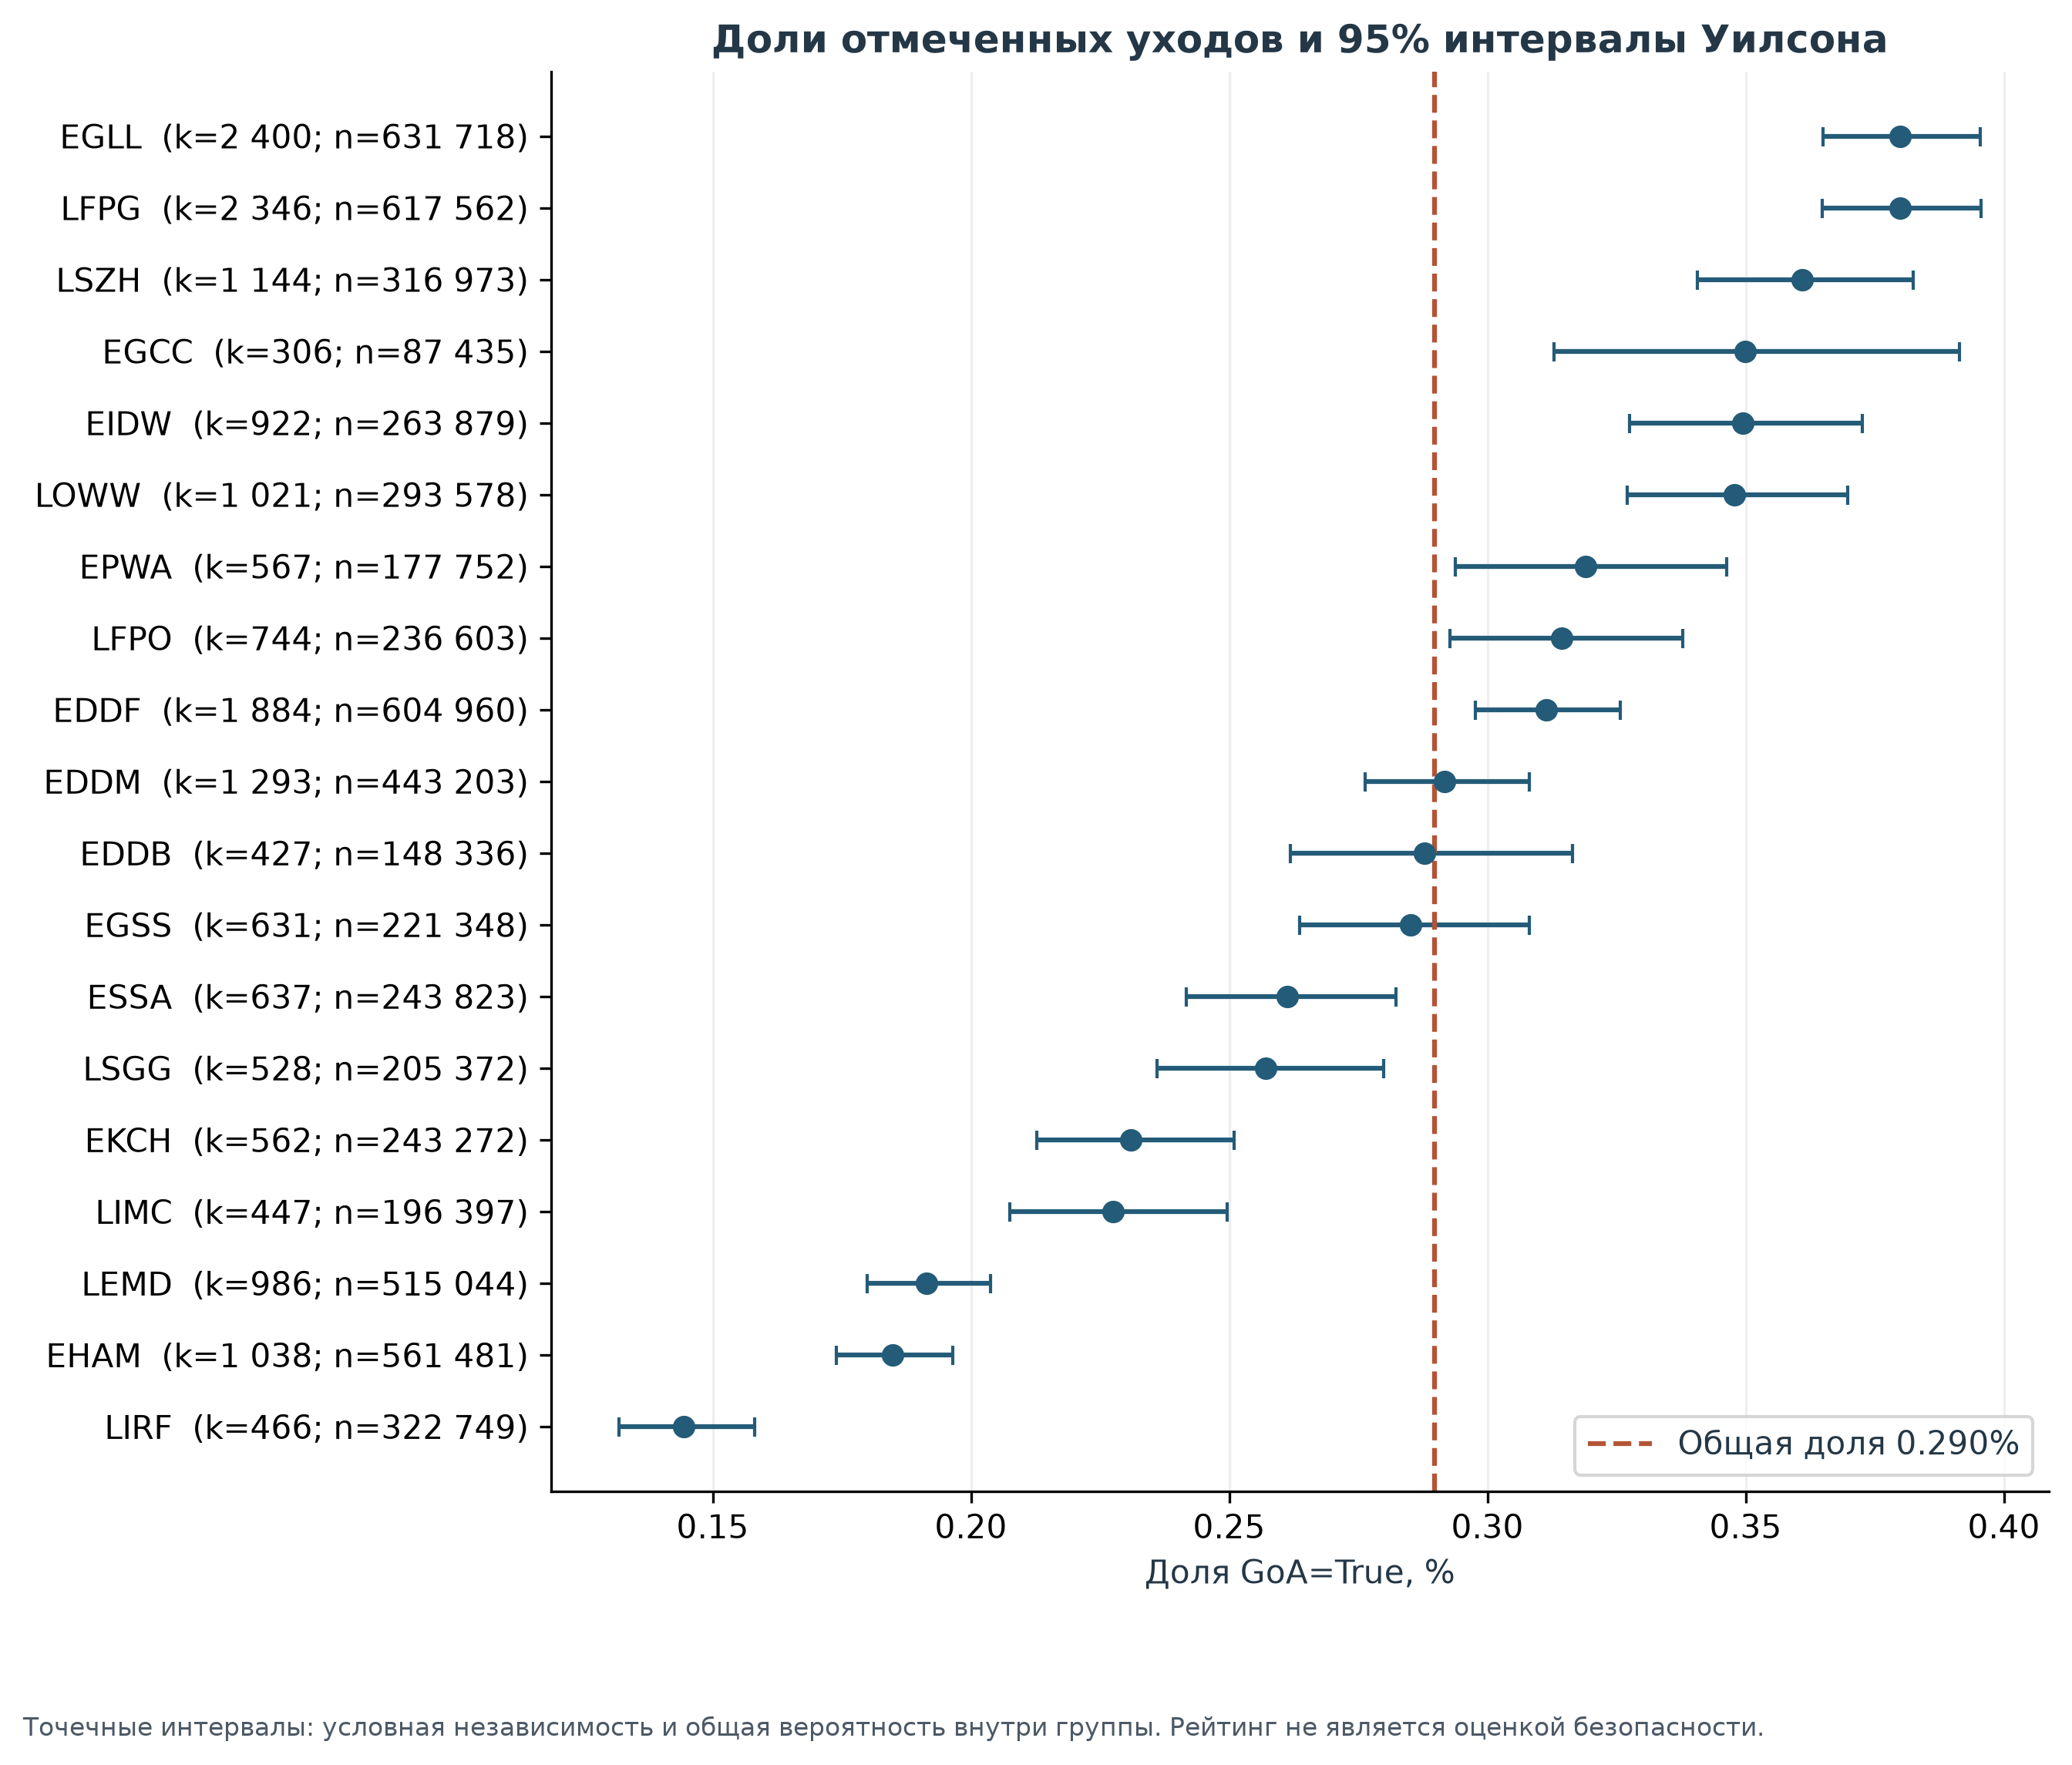

In [3]:
display(Image(filename=str(FIGURES / '07_02_airport_rates.png')))

## Покрытие по месяцам

Логарифмическая шкала показывает малые и крупные объемы. Отсутствие записи не доказывает отсутствие полетов.

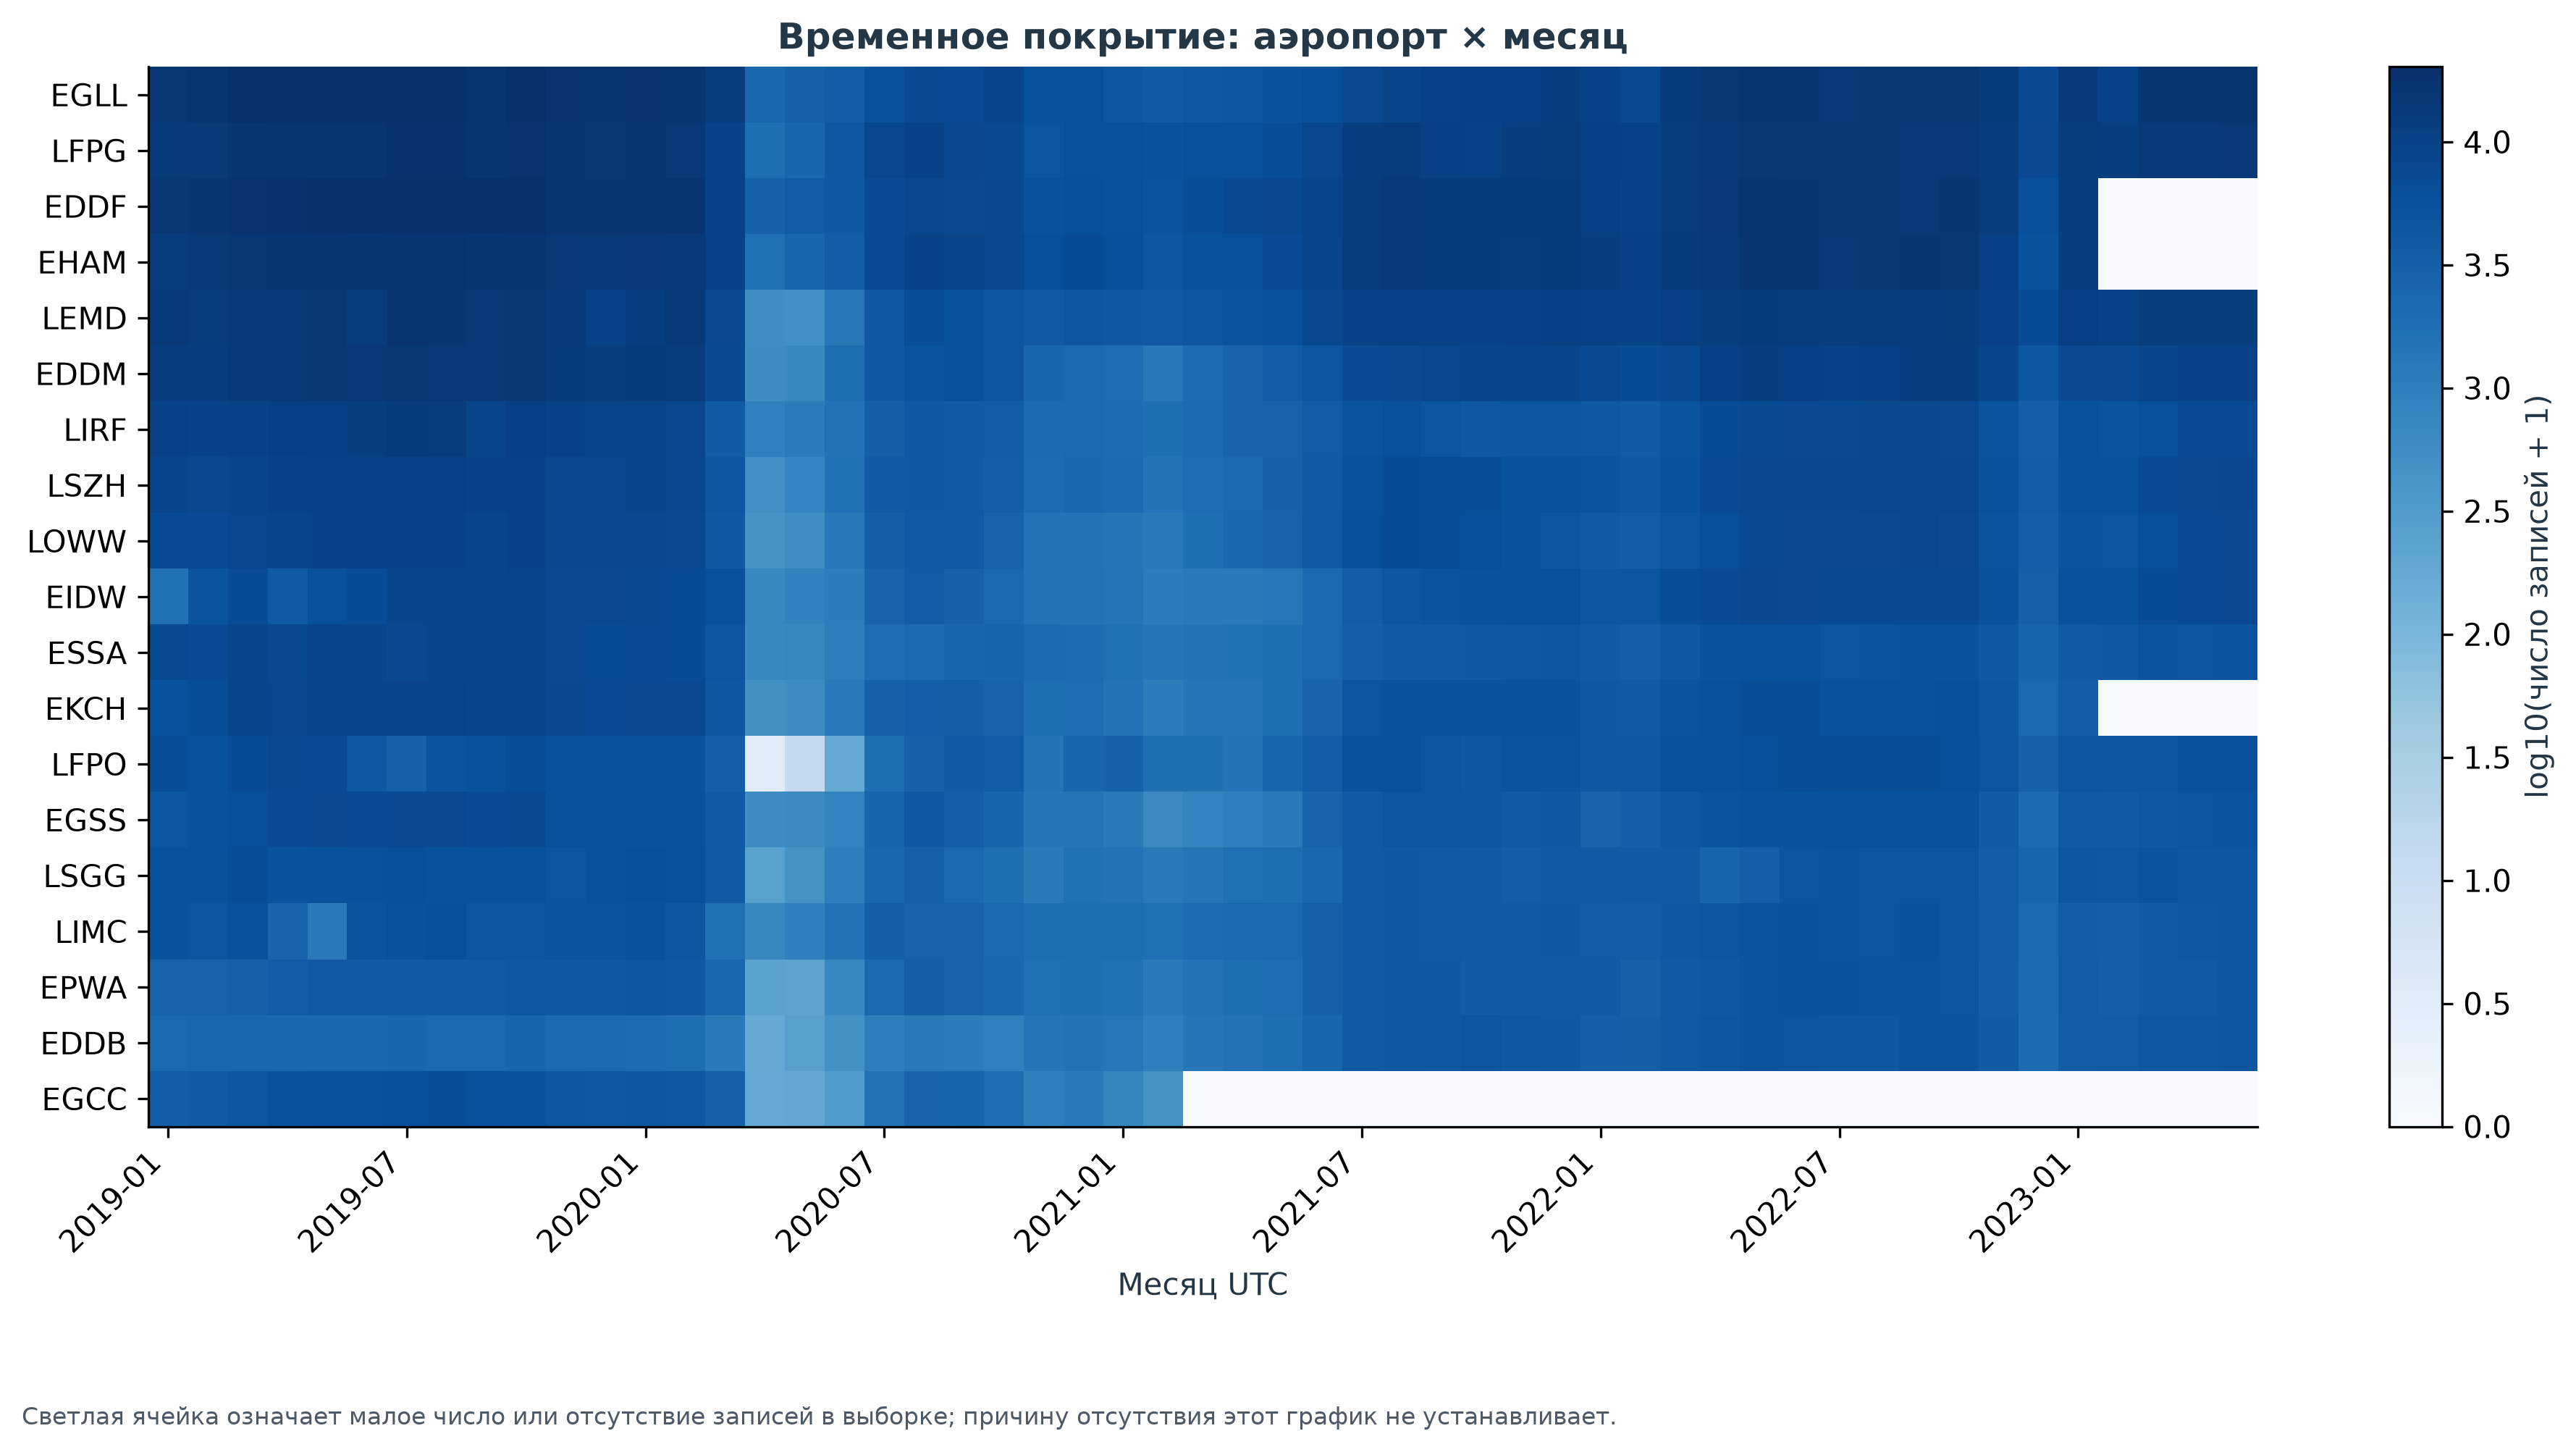

In [4]:
display(Image(filename=str(FIGURES / '07_03_monthly_coverage.png')))

## Аэропорт × месяц: доля GoA

Пустая группа не приравнивается к нулевой доле. Знаменатели и интервалы доступны в airport_month.csv.

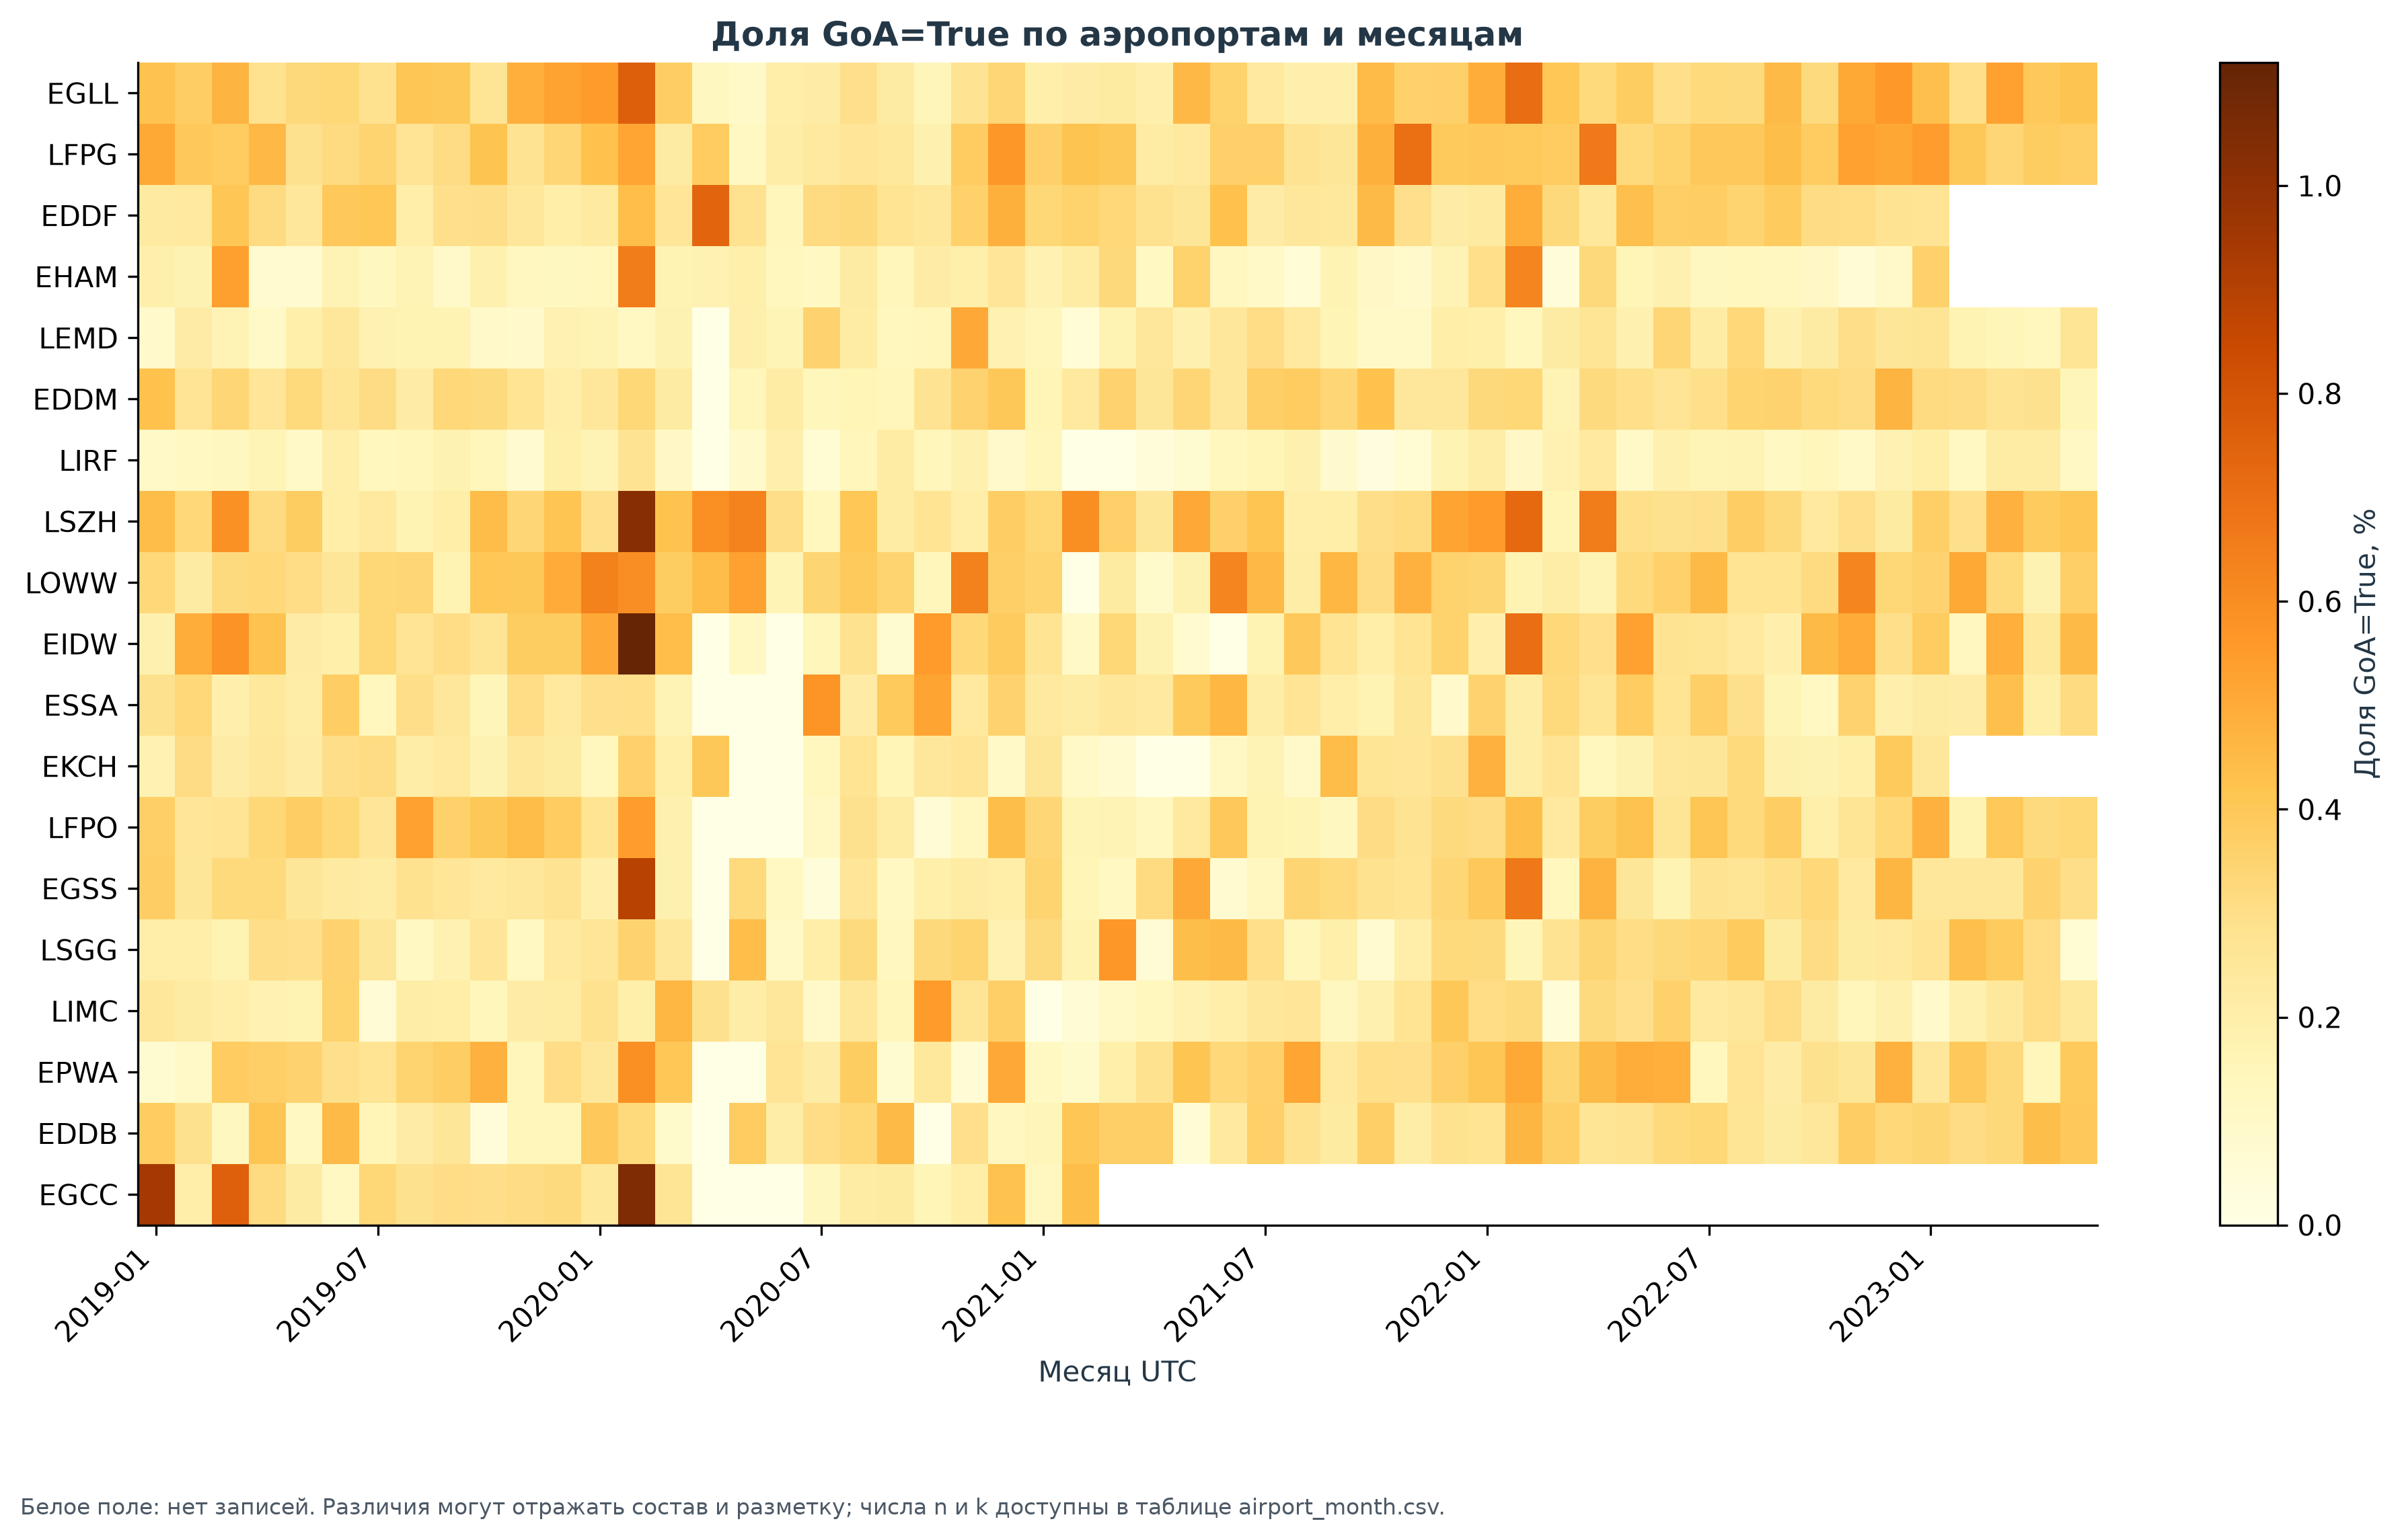

In [5]:
display(Image(filename=str(FIGURES / '07_04_monthly_rates.png')))

## Влияние отбора на оба класса

Сравнение исходного Parquet с актуальной выборкой после C40 и решений 04–06. Различия охвата могут изменить состав класса.

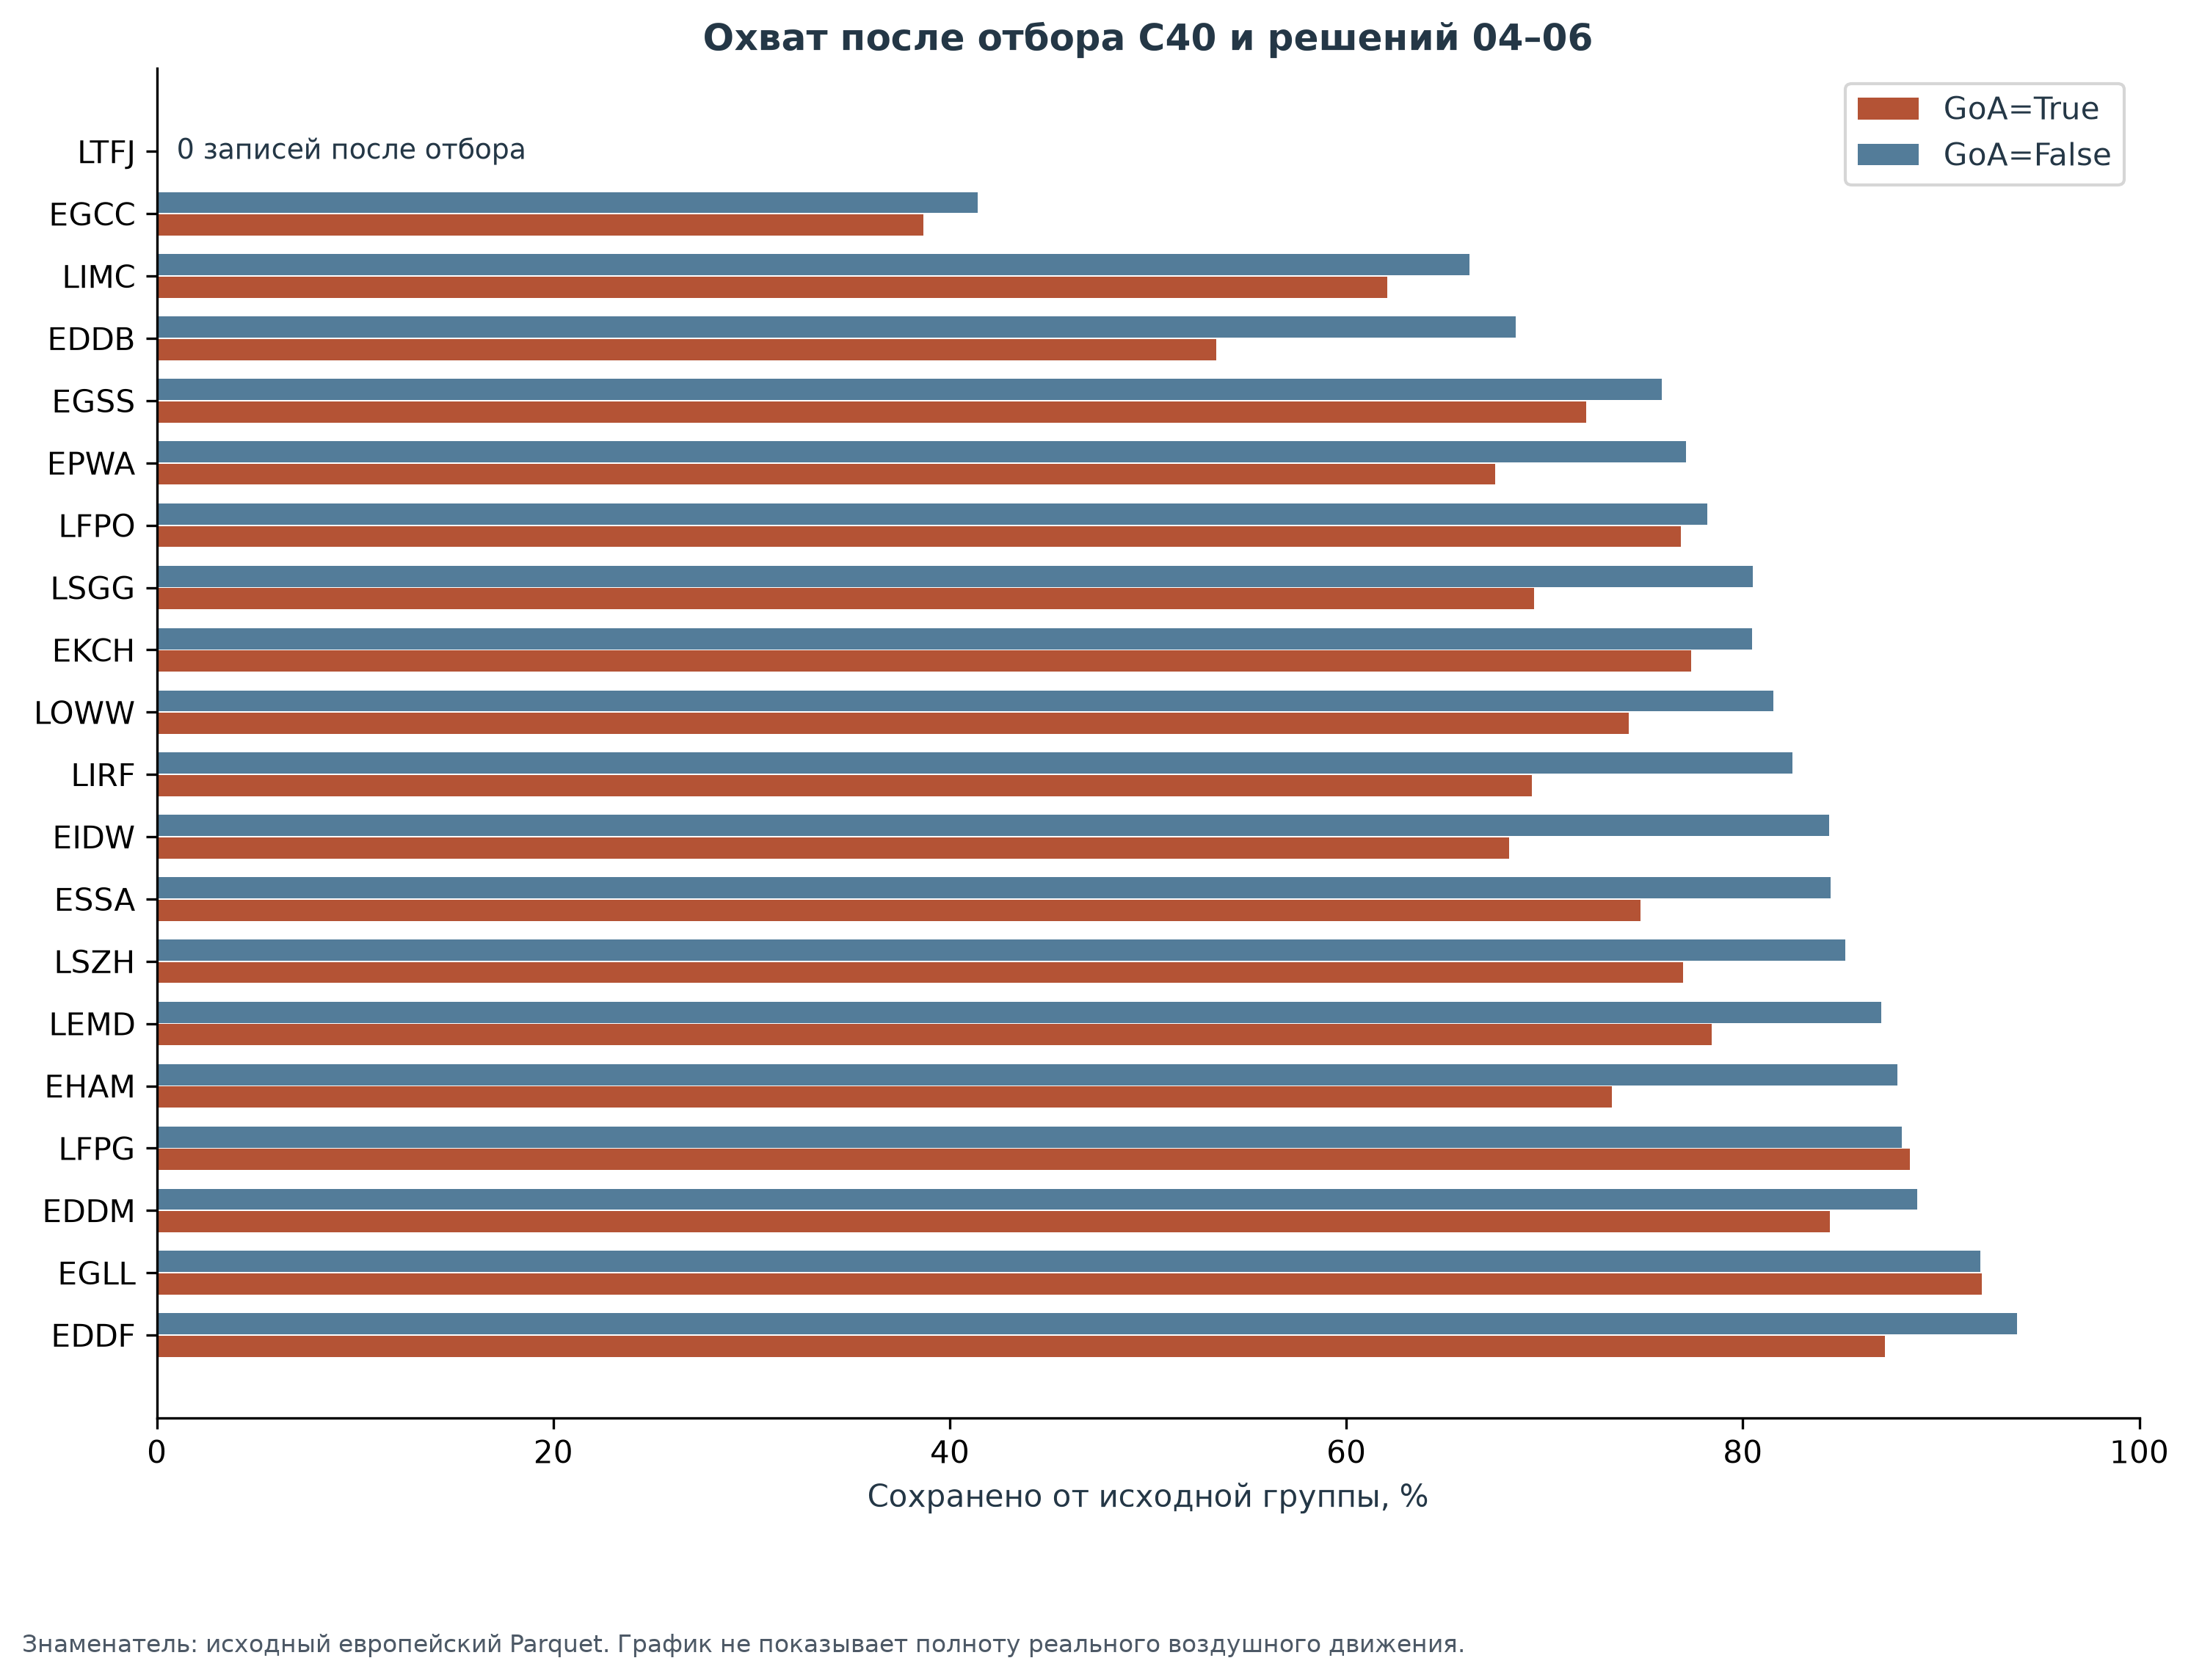

In [6]:
display(Image(filename=str(FIGURES / '07_05_selection_coverage.png')))

## Пропуски у GoA=True и GoA=False

Исходная и дополненная классификации показаны отдельно. Справочные поля не исправляются и не объявляются допустимыми признаками модели.

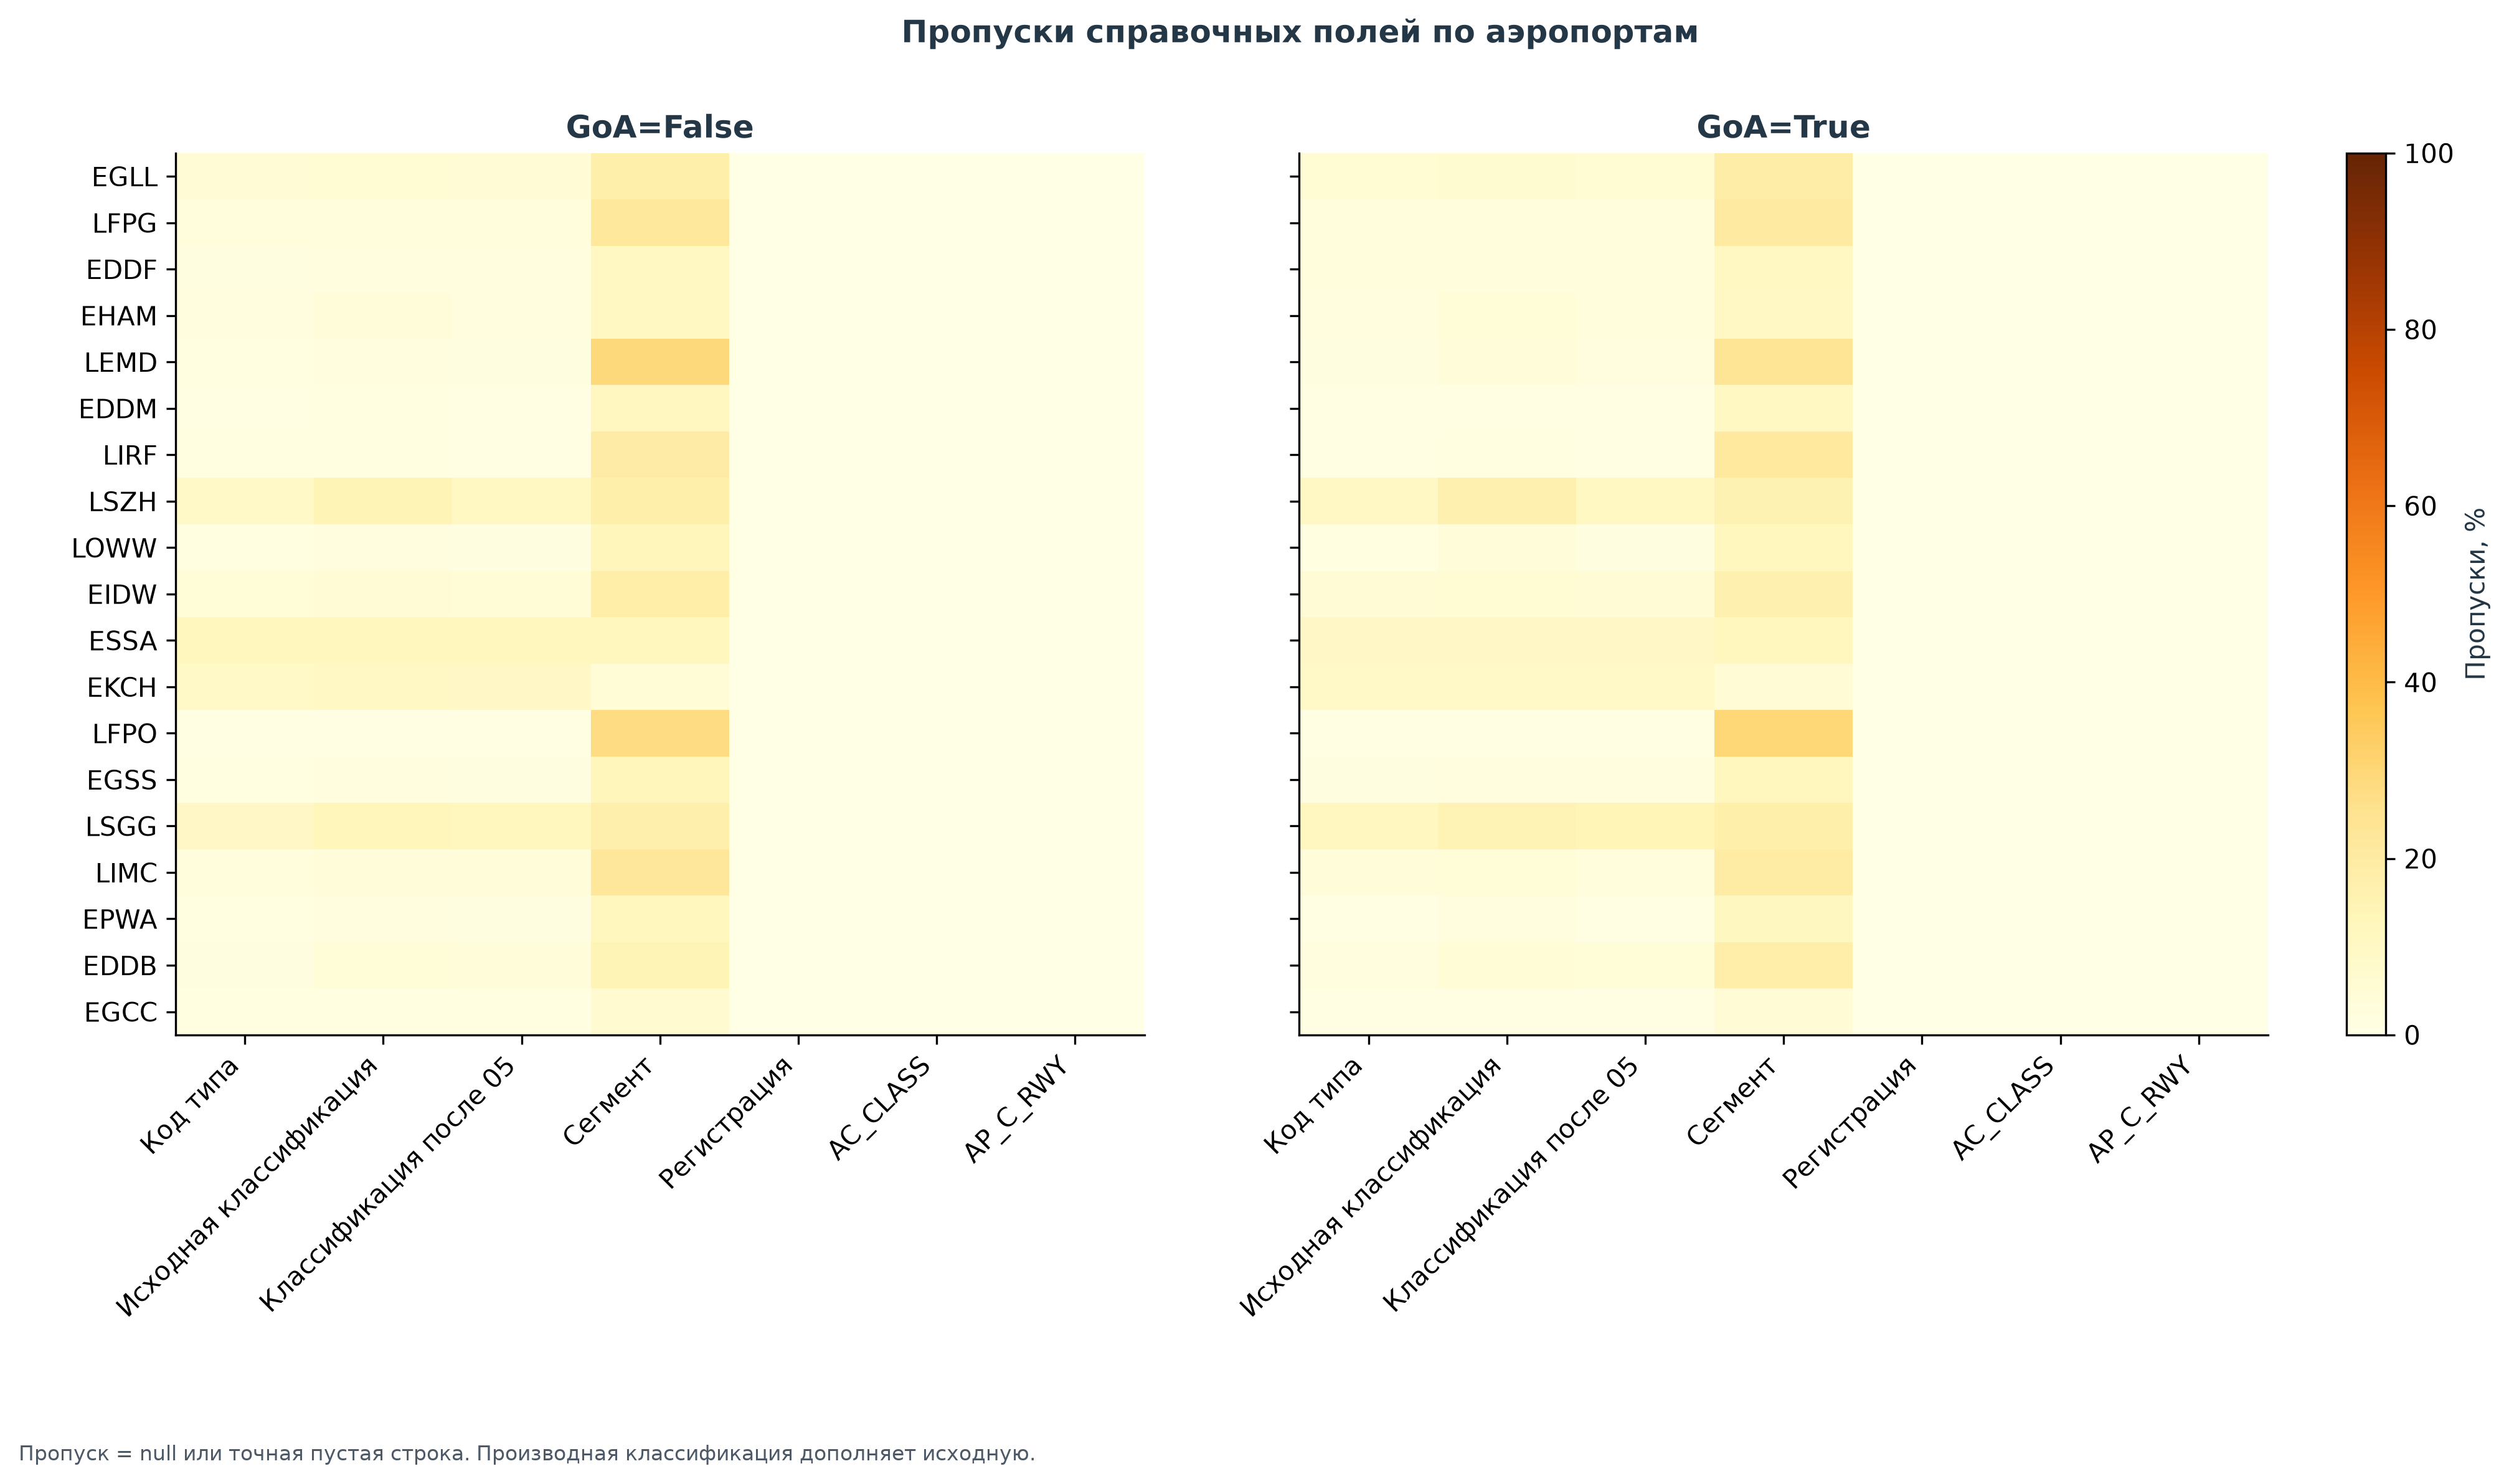

In [7]:
display(Image(filename=str(FIGURES / '07_06_missing_by_label.png')))

## Каждый аэропорт: временная динамика

Линия и точечный интервал по месяцам; шкалы Y различаются. Сравнивать абсолютный уровень следует по числам, а не высоте линии в разных панелях.

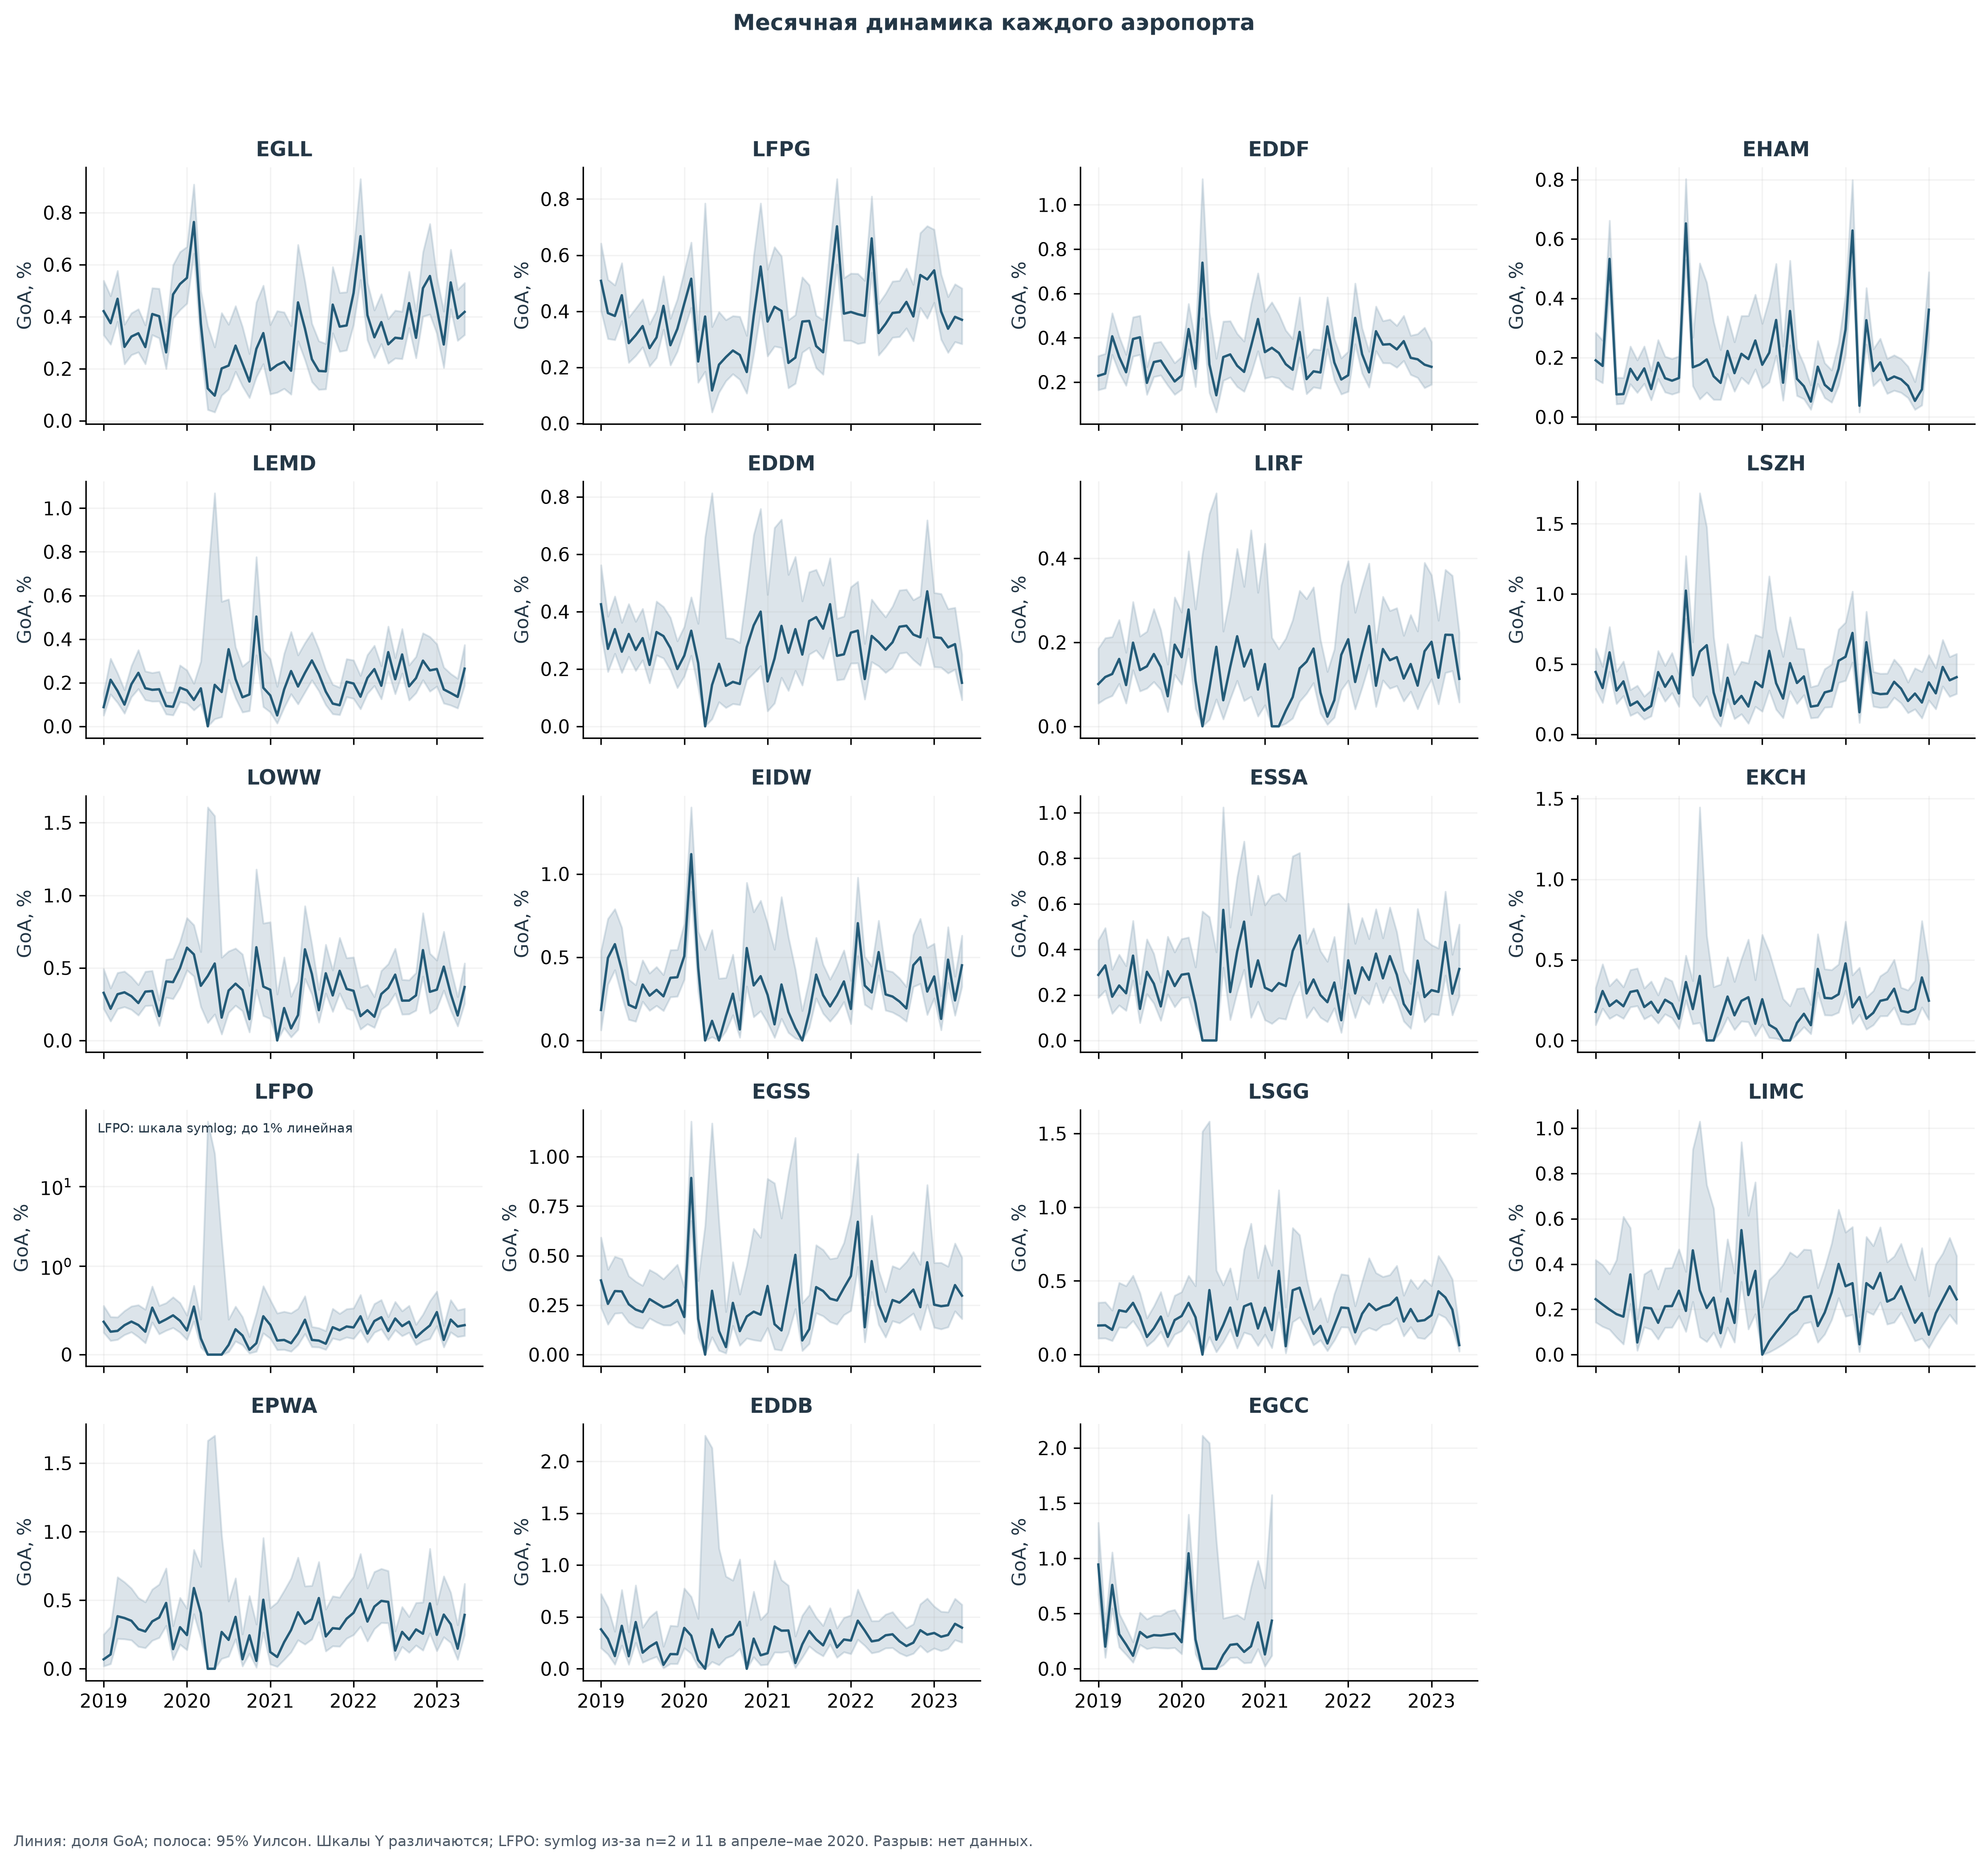

In [8]:
display(Image(filename=str(FIGURES / '07_07_airport_time_series.png')))

## Состав и кандидаты для дальнейшего разбора

Следующие таблицы описывают обе метки. Отбор 15 месяцев с наибольшей долей – способ просмотра, не статистический тест и не правило удаления.

In [9]:
display(pd.read_csv(REPORT / 'selection_coverage.csv'))
display(pd.read_csv(REPORT / 'highest_monthly_rates.csv'))
display(pd.read_csv(REPORT / 'missing_by_label.csv'))

,airport,rows,go_arounds,goa_false,ga_percent,wilson_lower_percent,wilson_upper_percent,max_deviation_pp,source_rows,source_go_arounds,retained_goa_percent,retained_non_goa_percent,retained_rows_percent,source_ga_percent
0,EDDB,148336,427,147909,0.287860,0.261853,0.316441,0.028581,216588,799,53.441802,68.543346,68.487636,0.368903
1,EDDF,604960,1884,603076,0.311426,0.297697,0.325785,0.014360,644881,2161,87.181860,93.831840,93.809556,0.335101
2,EDDM,443203,1293,441910,0.291740,0.276286,0.308055,0.016315,499206,1532,84.399478,88.795075,88.781585,0.306887
3,EGCC,87435,306,87129,0.349974,0.312952,0.391359,0.041385,211299,791,38.685209,41.389876,41.379751,0.374351
4,EGLL,631718,2400,629318,0.379916,0.365044,0.395392,0.015475,686819,2607,92.059839,91.977048,91.977362,0.379576
5,EGSS,221348,631,220717,0.285071,0.263707,0.308162,0.023090,291550,875,72.114286,75.932571,75.921111,0.300120
6,EHAM,561481,1038,560443,0.184868,0.173968,0.196450,0.011582,639766,1414,73.408769,87.795292,87.763495,0.221018
7,EIDW,263879,922,262957,0.349403,0.327600,0.372651,0.023248,313008,1352,68.195266,84.374118,84.304235,0.431938
8,EKCH,243272,562,242710,0.231017,0.212709,0.250897,0.019879,302339,726,77.410468,80.470669,80.463321,0.240128
9,EPWA,177752,567,177185,0.318984,0.293822,0.346293,0.027309,230593,840,67.500000,77.119776,77.084734,0.364278


,airport,month,rows,go_arounds,goa_false,ga_percent,wilson_lower_percent,wilson_upper_percent,max_deviation_pp
0,EIDW,2020-02,6705,75,6630,1.118568,0.893347,1.399769,0.281200
1,EGCC,2020-02,4301,45,4256,1.046268,0.782876,1.397029,0.350761
2,LSZH,2020-02,7914,81,7833,1.023503,0.824300,1.270229,0.246726
3,EGCC,2019-01,3494,33,3461,0.944476,0.673314,1.323387,0.378911
4,EGSS,2020-02,5489,49,5440,0.892694,0.675934,1.178142,0.285448
5,EGLL,2020-02,16622,127,16495,0.764048,0.642578,0.908270,0.144222
6,EGCC,2019-03,4606,35,4571,0.759878,0.546894,1.054928,0.295049
7,EDDF,2020-04,2977,22,2955,0.738999,0.488536,1.116429,0.377430
8,LSZH,2022-02,4432,32,4400,0.722022,0.511918,1.017475,0.295454
9,EGLL,2022-02,7328,52,7276,0.709607,0.541570,0.929294,0.219687


,airport,GoA,rows,registration,typecode,icaoaircrafttype,aircraft_description_restored,market_segment,AC_CLASS,AP_C_RWY,classification_unavailable,more_than_two_attempts,c40_not_before_landing,c40_coordinate_out_of_range
0,EDDB,False,147909,0,2761,6164,146737,21328,0,0,4992,0,0,0
1,EDDB,True,427,0,11,20,425,76,0,0,18,5,0,0
2,EDDF,False,603076,0,11216,13258,601972,64166,0,0,12154,0,0,0
3,EDDF,True,1884,0,54,58,1881,206,0,0,55,11,0,0
4,EDDM,False,441910,0,2701,5545,440577,50556,0,0,4212,0,0,0
5,EDDM,True,1293,0,9,15,1287,132,0,0,9,6,0,0
6,EGCC,False,87129,0,1137,1329,87038,5507,0,0,1238,0,0,0
7,EGCC,True,306,0,2,2,306,16,0,0,2,1,0,0
8,EGLL,False,629318,0,33466,34473,628274,109196,0,0,33429,0,0,0
9,EGLL,True,2400,0,137,142,2395,442,0,0,137,15,0,0


## Методика, результаты и продолжение

Полный отчет расположен рядом с агрегатами. Интервалы не являются одновременными и не учитывают кластерную зависимость. Архивные исключения и допуск 0,2 п.п. на новую выборку не перенесены. Следующий шаг 07_02 – отдельный разбор аэропортов, выделенных обзором; исходные значения сохраняются.

In [10]:
display(Markdown((REPORT / '07_01_review.md').read_text(encoding='utf8')))

# 07_01 – Аэропорты: полный описательный аудит

Проверены 6,331,485 строк: 18,349 GoA=True и 6,313,136 GoA=False; 19 аэропортов. Обе метки охвачены полностью. Вход и исходник проверены по SHA256 до и после; изменения и исключения отсутствуют.

## Сводка по аэропортам

| Аэропорт | n | k GoA | Доля, % | 95% Уилсон, % | Активных месяцев | Дней без записей | Сохранено исходных строк, % |
| --- | ---: | ---: | ---: | --- | ---: | ---: | ---: |
| EGLL | 631,718 | 2,400 | 0.380 | 0.365–0.395 | 53 | 36 | 92.0 |
| LFPG | 617,562 | 2,346 | 0.380 | 0.365–0.396 | 53 | 23 | 88.0 |
| EDDF | 604,960 | 1,884 | 0.311 | 0.298–0.326 | 49 | 147 | 93.8 |
| EHAM | 561,481 | 1,038 | 0.185 | 0.174–0.196 | 49 | 146 | 87.8 |
| LEMD | 515,044 | 986 | 0.191 | 0.180–0.204 | 53 | 25 | 87.0 |
| EDDM | 443,203 | 1,293 | 0.292 | 0.276–0.308 | 53 | 31 | 88.8 |
| LIRF | 322,749 | 466 | 0.144 | 0.132–0.158 | 53 | 24 | 82.5 |
| LSZH | 316,973 | 1,144 | 0.361 | 0.341–0.382 | 53 | 25 | 85.1 |
| LOWW | 293,578 | 1,021 | 0.348 | 0.327–0.370 | 53 | 24 | 81.5 |
| EIDW | 263,879 | 922 | 0.349 | 0.328–0.373 | 53 | 25 | 84.3 |
| ESSA | 243,823 | 637 | 0.261 | 0.242–0.282 | 53 | 24 | 84.4 |
| EKCH | 243,272 | 562 | 0.231 | 0.213–0.251 | 49 | 148 | 80.5 |
| LFPO | 236,603 | 744 | 0.314 | 0.293–0.338 | 53 | 80 | 78.2 |
| EGSS | 221,348 | 631 | 0.285 | 0.264–0.308 | 53 | 24 | 75.9 |
| LSGG | 205,372 | 528 | 0.257 | 0.236–0.280 | 53 | 25 | 80.5 |
| LIMC | 196,397 | 447 | 0.228 | 0.207–0.250 | 53 | 24 | 66.2 |
| EPWA | 177,752 | 567 | 0.319 | 0.294–0.346 | 53 | 25 | 77.1 |
| EDDB | 148,336 | 427 | 0.288 | 0.262–0.316 | 53 | 25 | 68.5 |
| EGCC | 87,435 | 306 | 0.350 | 0.313–0.391 | 26 | 823 | 41.4 |

## Интерпретация и дальнейший разбор

Самые высокие наблюдаемые доли: EGLL (0.380%, k=2400, n=631718), LFPG (0.380%, k=2346, n=617562), LSZH (0.361%, k=1144, n=316973). Это описательная характеристика разметки, а не рейтинг безопасности.

Наименьший охват исходных строк: EGCC (41.4%), LIMC (66.2%), EDDB (68.5%). Дальше нужно разделить влияние отбора по C40, исходного покрытия и состава полетов.

`highest_monthly_rates.csv` содержит 15 месяцев с наибольшей долей, с n, k и интервалами; это ранжирование без автоматического порога удаления. Неполные крайние годы и общие провалы покрытия проверяются по календарным таблицам, а не трактуются как изменение авиационного риска.

## Метод и ограничения

Единица учета – сохраненная запись посадочного сегмента, не гарантированно уникальный физический полет. Интервал Уилсона 95% рассчитан по [формуле NIST](https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm). Интервалы точечные, не одновременные; зависимость наблюдений одного борта и календарных групп не устранена. Они описывают биномиальную неопределенность при условных предположениях, а не погрешность детектора и не репрезентативность реального движения. Архивный допуск 0,2 п.п. не применен как правило к новой Европе.

GoA=False означает отсутствие отмеченного ухода, а не независимое подтверждение нормального профиля. Реальное число операций аэропорта неизвестно; охват измеряется относительно исходного Parquet. Изменение доли между исходником и выборкой не устанавливает причину. Типы и сегменты описаны отдельно по обеим меткам; пропуски не заполнены. Производная классификация дополняет исходную только там, где выполнены правила этапа 05.

LSGG остается с принятой оговоркой; план чувствительности из этапа 06 сохраняется. Никакие новые аэропорты и строки не исключены. Углубленный разбор отдельных аэропортов – следующий шаг 07_02, после обсуждения обнаруженных групп. Подготовка идентификатора и окончательный допуск признаков идут после аэропортового разбора.


В исходнике 20 аэропортов; в текущей выборке 19. LTFJ не содержит сохраненных строк после отбора C40: исходно 387 368 строк, 2 414 GoA=True. Охват обеих меток – 0%; частота GoA в пустой группе не вычисляется. Это результат прежнего отбора, а не новое исключение этапа 07.


LFPO в апреле и мае 2020 имеет только 2 и 11 записей (обе месячные группы без GoA). Верхние границы точечного 95% интервала составляют 65,762% и 25,883%; нулевая наблюдаемая доля не дает точной оценки вероятности. В панели LFPO использована явно обозначенная шкала symlog: до 1% линейная, выше логарифмическая, чтобы сохранить полные интервалы. Это вопрос малого знаменателя и покрытия, а не доказательство смены риска.


## Карточки каждого аэропорта

[Все 20 аэропортов исходника](../../reports/airports/airport_profiles.md): непрерывные провалы, пропуски, наиболее частые типы и сегменты отдельно для GoA=True и GoA=False. LTFJ представлен как аэропорт без сохраненных наблюдений. [Навигация и определения полей](../../reports/airports/README.md).